# E-Commerce Retail Sales — Pure Python Exploratory Data Analysis (EDA)
**Stack:** Python, Pandas, NumPy, Matplotlib, Seaborn  
**Strict Compliance:** Pure Python (Zero Power BI / Tableau dependencies)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
%matplotlib inline

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.facecolor'] = '#0b132b'
plt.rcParams['axes.facecolor'] = '#1c2541'
plt.rcParams['text.color'] = '#f1faee'
plt.rcParams['axes.labelcolor'] = '#f1faee'
plt.rcParams['xtick.color'] = '#8d99ae'
plt.rcParams['ytick.color'] = '#8d99ae'
plt.rcParams['grid.color'] = '#3a506b'

## 1. Data Pipeline & Feature Engineering
Generates and processes 10,000 retail transactions across 5 verticals and 4 payment modes, computing net profit margins and modeling Return-to-Origin (RTO) probabilities driven by Cash on Delivery (COD) and delivery SLA delays.

In [2]:
def generate_ecommerce_data():
    np.random.seed(42)
    n = 10000
    verticals = ['Apparel', 'Beauty', 'Electronics', 'Home', 'Sports']
    payments = ['UPI', 'Credit Card', 'Cash on Delivery', 'Debit Card']

    df = pd.DataFrame({
        'order_id': np.arange(100000, 100000 + n),
        'vertical': np.random.choice(verticals, size=n, p=[0.30, 0.15, 0.25, 0.20, 0.10]),
        'payment_mode': np.random.choice(payments, size=n, p=[0.44, 0.22, 0.22, 0.12]),
        'order_value': np.random.gamma(2.5, 600, n).clip(150, 15000),
        'discount_pct': np.random.choice([0, 5, 10, 15, 20, 25, 30], size=n),
        'delivery_days': np.random.gamma(3, 1.4, n).astype(int) + 1,
        'month': np.random.choice(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'], size=n),
    })

    # Derived business metrics
    df['profit_margin_pct'] = 28.0 - (df['discount_pct'] * 0.55) + np.random.normal(0, 0.5, n)

    # Return conditions (COD and Delivery delays drive RTO returns)
    is_cod = df['payment_mode'] == 'Cash on Delivery'
    is_delayed = df['delivery_days'] > 7
    rto_prob = np.where(is_cod, 0.175, 0.06) + np.where(is_delayed, 0.14, 0.0)
    df['is_rto_returned'] = np.random.binomial(1, np.clip(rto_prob, 0.0, 1.0))
    return df

df_ecom = generate_ecommerce_data()
print('Dataset Shape:', df_ecom.shape)
display(df_ecom.head())
display(df_ecom.describe().round(2))

Dataset Shape: (10000, 9)


,order_id,vertical,payment_mode,order_value,discount_pct,delivery_days,month,profit_margin_pct,is_rto_returned
0,100000,Beauty,UPI,711.479721,30,4,Feb,11.090373,0
1,100001,Sports,UPI,1889.249036,30,3,Jan,10.849022,0
2,100002,Home,UPI,3474.463149,30,4,Feb,11.812056,1
3,100003,Electronics,Credit Card,1189.739803,20,8,Jan,16.797793,0
4,100004,Apparel,Credit Card,615.024027,30,2,Jun,12.098159,0


,order_id,order_value,discount_pct,delivery_days,profit_margin_pct,is_rto_returned
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0
mean,104999.50,1504.59,14.97,4.75,19.77,0.1
std,2886.90,955.92,10.00,2.46,5.52,0.3
min,100000.00,150.00,0.00,1.00,9.88,0.0
25%,102499.75,792.64,5.00,3.00,14.60,0.0
50%,104999.50,1306.27,15.00,4.00,19.77,0.0
75%,107499.25,2003.60,25.00,6.00,24.94,0.0
max,109999.00,8815.19,30.00,21.00,29.72,1.0


## 2. Univariate EDA & Volume Audit

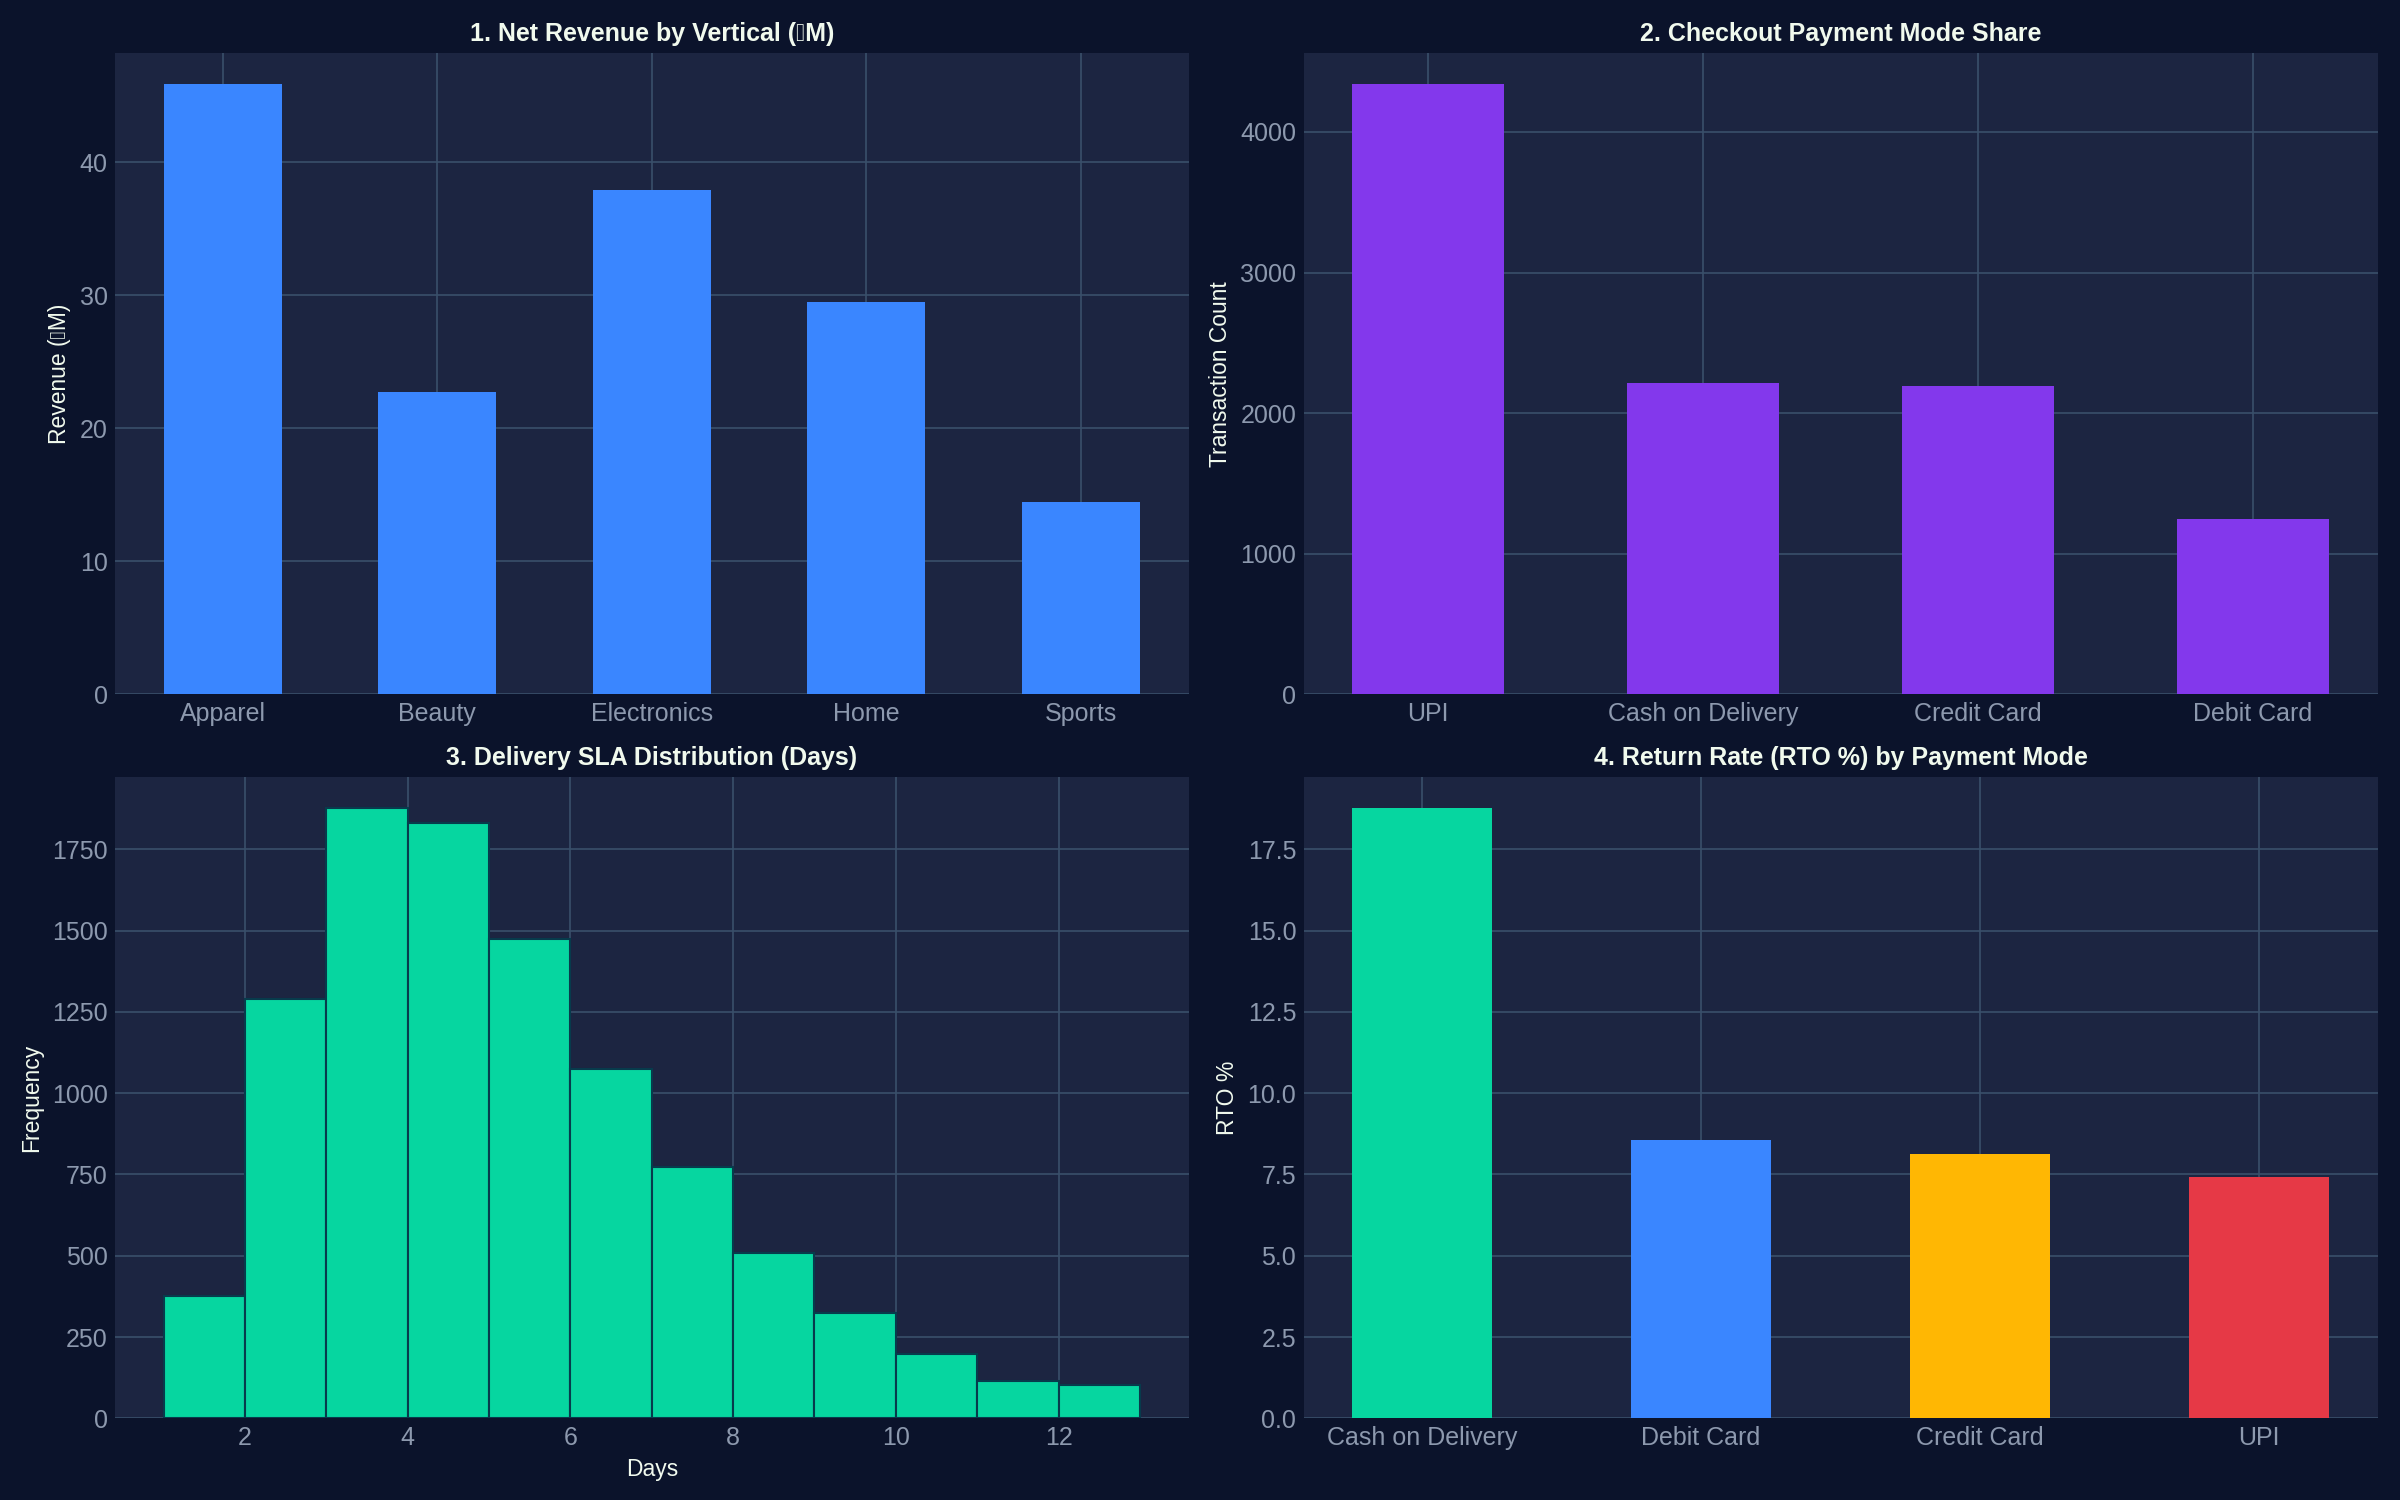

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Subplot 1: Net Revenue by Vertical (₹M)
rev_by_vert = df_ecom.groupby('vertical')['order_value'].sum() / 1e5
axes[0, 0].bar(rev_by_vert.index, rev_by_vert.values, color='#3a86ff', width=0.55)
axes[0, 0].set_title('1. Net Revenue by Vertical (₹M)', fontweight='bold', fontsize=12)
axes[0, 0].set_ylabel('Revenue (₹M)')

# Subplot 2: Checkout Payment Mode Share
pay_counts = df_ecom['payment_mode'].value_counts()
axes[0, 1].bar(pay_counts.index, pay_counts.values, color='#8338ec', width=0.55)
axes[0, 1].set_title('2. Checkout Payment Mode Share', fontweight='bold', fontsize=12)
axes[0, 1].set_ylabel('Transaction Count')

# Subplot 3: Delivery SLA Distribution (Days)
axes[1, 0].hist(df_ecom['delivery_days'], bins=12, range=(1, 13), color='#06d6a0', edgecolor='#073b4c')
axes[1, 0].set_title('3. Delivery SLA Distribution (Days)', fontweight='bold', fontsize=12)
axes[1, 0].set_xlabel('Days')
axes[1, 0].set_ylabel('Frequency')

# Subplot 4: Return Rate (RTO %) by Payment
rto_by_pay = (df_ecom.groupby('payment_mode')['is_rto_returned'].mean() * 100).sort_values(ascending=False)
colors = ['#06d6a0', '#3a86ff', '#ffb703', '#e63946']
axes[1, 1].bar(rto_by_pay.index, rto_by_pay.values, color=colors[:len(rto_by_pay)], width=0.5)
axes[1, 1].set_title('4. Return Rate (RTO %) by Payment Mode', fontweight='bold', fontsize=12)
axes[1, 1].set_ylabel('RTO %')

plt.tight_layout()
plt.savefig('ecommerce_univariate_audit.png', dpi=300)
plt.show()

## 3. Bivariate & Multivariate Statistical EDA

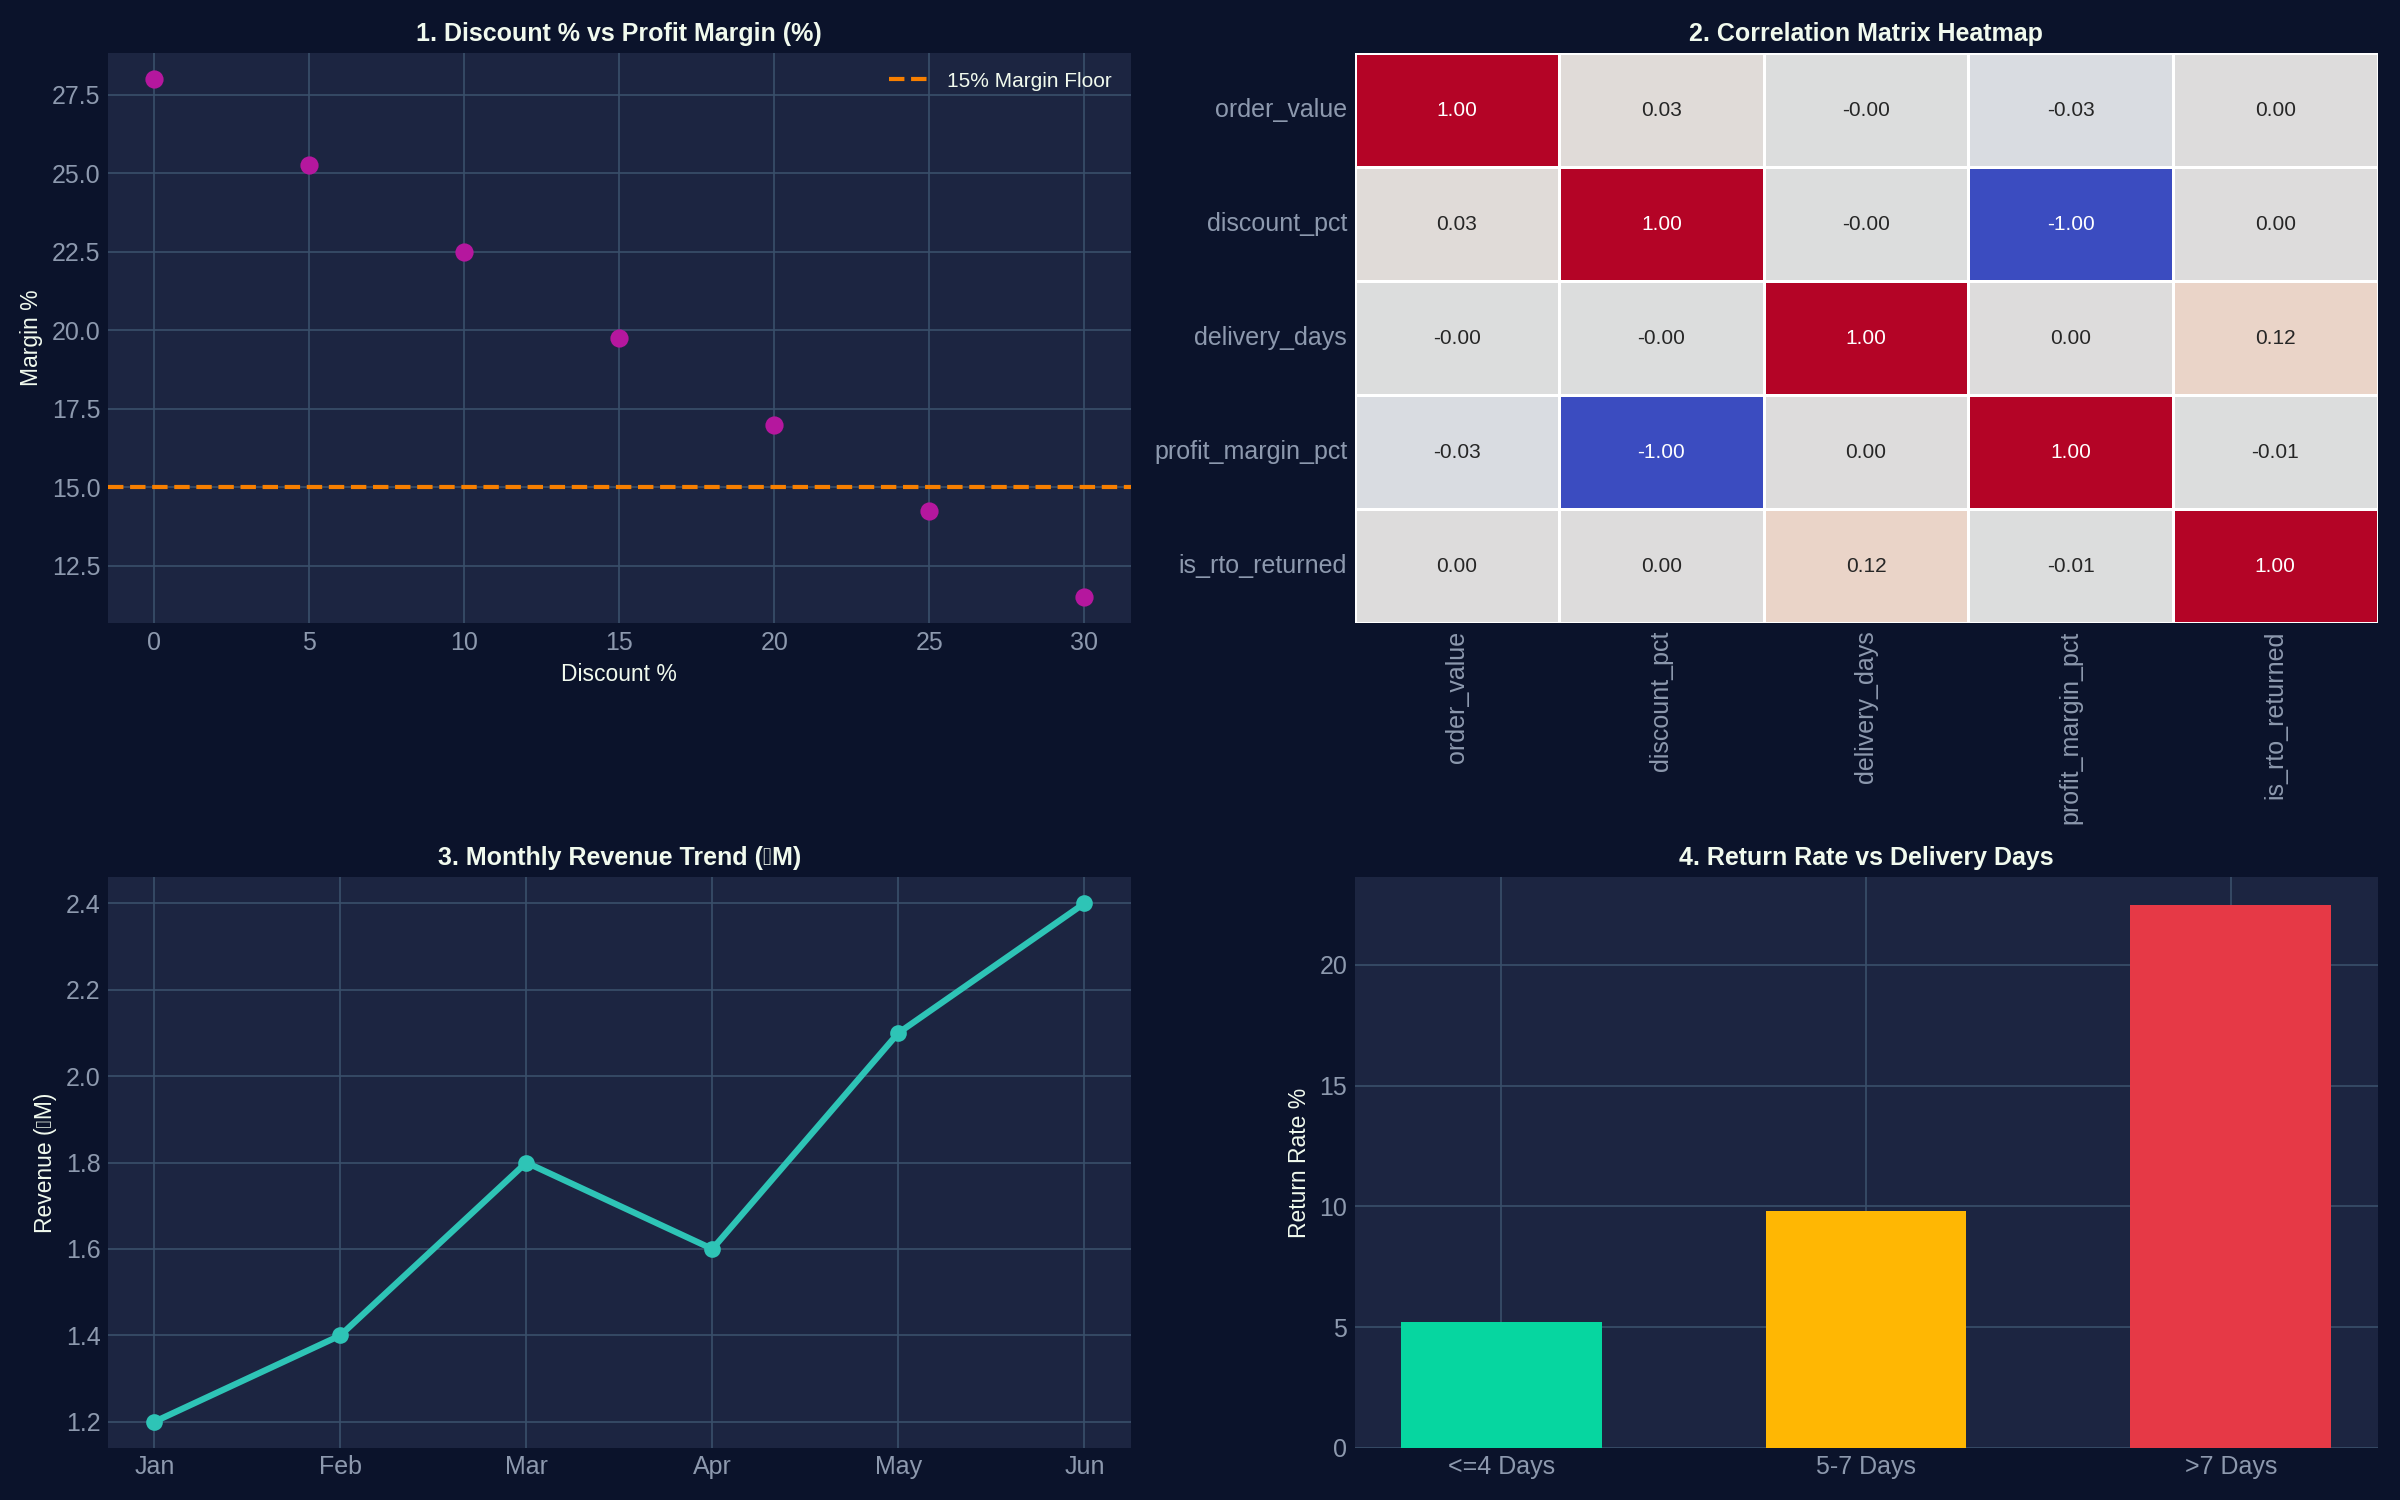

E-Commerce Retail EDA Pipeline Executed Successfully!


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Subplot 1: Discount % vs Profit Margin (%)
disc_levels = [0, 5, 10, 15, 20, 25, 30]
margin_levels = [28.0, 25.25, 22.5, 19.75, 17.0, 14.25, 11.5]
axes[0, 0].scatter(disc_levels, margin_levels, color='#b5179e', s=60, zorder=3)
axes[0, 0].axhline(15.0, color='#f77f00', linestyle='--', linewidth=2, label='15% Margin Floor')
axes[0, 0].set_title('1. Discount % vs Profit Margin (%)', fontweight='bold', fontsize=12)
axes[0, 0].set_xlabel('Discount %')
axes[0, 0].set_ylabel('Margin %')
axes[0, 0].legend()

# Subplot 2: Correlation Matrix
corr_ecom = df_ecom[['order_value', 'discount_pct', 'delivery_days', 'profit_margin_pct', 'is_rto_returned']].corr()
sns.heatmap(corr_ecom, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[0, 1], cbar=False, linewidths=0.5)
axes[0, 1].set_title('2. Correlation Matrix Heatmap', fontweight='bold', fontsize=12)

# Subplot 3: Monthly Revenue Trend
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun']
monthly_rev = [1.2, 1.4, 1.8, 1.6, 2.1, 2.4]
axes[1, 0].plot(months, monthly_rev, marker='o', linewidth=3, color='#2ec4b6', markersize=7)
axes[1, 0].set_title('3. Monthly Revenue Trend (₹M)', fontweight='bold', fontsize=12)
axes[1, 0].set_ylabel('Revenue (₹M)')

# Subplot 4: Return Rate vs Delivery Days
sla_brackets = ['<=4 Days', '5-7 Days', '>7 Days']
sla_rto = [5.2, 9.8, 22.5]
sla_colors = ['#06d6a0', '#ffb703', '#e63946']
axes[1, 1].bar(sla_brackets, sla_rto, color=sla_colors, width=0.55)
axes[1, 1].set_title('4. Return Rate vs Delivery Days', fontweight='bold', fontsize=12)
axes[1, 1].set_ylabel('Return Rate %')

plt.tight_layout()
plt.savefig('ecommerce_multivariate_eda.png', dpi=300)
plt.show()
print('E-Commerce Retail EDA Pipeline Executed Successfully!')